### Image Binarization Using a Time-Fractional Diffusion–Reaction Equation

In this method, the original image is used as the initial condition of the equation

$$
{}^{C}D_t^\alpha u
= c_d\Delta u+c_su(1-u)(u-a).
$$

The diffusion term, $\Delta u$, helps to smooth the image and reduce noise. The reaction term, $c_su(1-u)(u-a)$, helps the pixel values move towards $0$ or $1$, producing a binary image.

The fractional order, $\alpha$, controls how the solution evolves over time. When $\alpha=1$, we have the usual first-order time derivative. When $0<\alpha<1$, the fractional derivative accounts for the history of the solution.

For our numerical implementation, we use finite differences with a 5-point stencil to approximate the spatial derivatives. We apply Neumann boundary conditions at the image edges and use the L1 scheme to approximate the Caputo fractional derivative in time.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from math import gamma
from PIL import Image
from PIL import Image, ImageDraw, ImageFont
from matplotlib.colors import Normalize, LightSource, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable

### Normalization and the Laplacian

The `normalize` function scales the pixel values to the range \([0,1]\), so they match the values used by the source term \(f(u)\).

The `laplacian_neumann` function uses the 5-point stencil to calculate the Laplacian. It uses the pixel above, below, to the left, to the right, and the centre pixel.

We use `mode="edge"` to copy the edge pixels when padding the image. This helps us apply the Neumann boundary condition, where there is no flow across the image boundaries.

In [ ]:
def normalize(img):
    img = img.astype(float)
    return (img - img.min()) / (img.max() - img.min() + 1e-12)


def laplacian_neumann(u, h=1.0):
    u = np.pad(u, 1, mode="edge")

    return (u[:-2, 1:-1] + u[2:, 1:-1]
            + u[1:-1, :-2] + u[1:-1, 2:]
            - 4 * u[1:-1, 1:-1]) / h**2



For now, we use a simple cubic function as a placeholder:

\[
f(u) = u(1-u)(u-\theta).
\]

This function helps move the pixel values towards 0 (black) or 1 (white), depending on the value of \(\theta\).

We use this function for now because we have not yet found the exact source term used in the paper. Once we find it, we can replace this function with the one from the paper.

In [ ]:
def f(u, a=0.5, c_s=50.0):
    return c_s * u * (1 - u) * (u - a)

### Step 4: The L1 Time-Stepping Scheme

The L1 scheme approximates the Caputo fractional derivative using the current and previous time steps.

$$
{}^{C}D_t^\alpha u(t_{n+1})
\approx
c\sum_{k=0}^{n}b_k
\left(u^{n+1-k}-u^{n-k}\right)
$$

where

$$
b_k=(k+1)^{1-\alpha}-k^{1-\alpha}
$$

and

$$
c=\frac{1}{\Gamma(2-\alpha)(\Delta t)^\alpha}.
$$

We evaluate the Laplacian and the reaction term at the previous time step. This gives the following explicit update:

$$
u^{n+1}
=
u^n-\mathrm{mem}
+\frac{1}{c}
\left[
c_d\Delta_h u^n
+c_su^n(1-u^n)(u^n-a)
\right],
$$

where $\Delta_h$ is the finite-difference approximation of the Laplacian.

The `mem` variable stores the contribution from previous time steps. This allows the fractional method to account for the history of the solution.

The `dt_from_lambda` function chooses the time step using the fractional order $\alpha$ and the parameter `LAM`. If the solution becomes unstable or produces `NaN` values, we can try a smaller value of `LAM`.

The `window` option limits the memory calculation to the most recent time steps. This reduces computation time for larger images, but ignores older contributions and therefore approximates the full memory term.

In [ ]:
def dt_from_lambda(alpha, lam):
    return (lam / gamma(2 - alpha)) ** (1 / alpha)


def solve(u0, alpha, dt, n_steps, h=1.0,
          a=0.5, c_d=1.0, c_s=50.0, window=None):

    c = dt**(-alpha) / gamma(2 - alpha)
    k = np.arange(n_steps + 1)
    b = (k + 1)**(1 - alpha) - k**(1 - alpha)

    u = u0.copy()
    diffs = []
    traj = [u.copy()]

    for n in range(n_steps):
        rhs = c_d * laplacian_neumann(u, h) + f(u, a, c_s)

        hist = diffs if window is None else diffs[-window:]
        mem = np.zeros_like(u)

        for kk in range(1, len(hist) + 1):
            mem += b[kk] * hist[-kk]

        u_new = u - mem + rhs / c
        diffs.append(u_new - u)
        u = u_new
        traj.append(u.copy())

    return traj

###  The Error Metric

We convert the solution into a binary image by setting pixel values greater than or equal to \(0.5\) to 1 and the remaining values to 0. We then compare this image with the binary ground truth.

The error metric measures how different the resulting image is from the ground truth. We use the **mean absolute error (L1 error)** to calculate the average difference between their pixel values.

For binary images, this is also the fraction of pixels that are incorrect. We multiply it by 100 to get the percentage of wrong pixels.

The error is calculated at each time step so that we can see how the image changes over time and compare our results with Figure 8 in the paper.

In [ ]:
def l1_error(u, gt, thresh=0.5):
    u = (u > thresh).astype(float)
    error = np.abs(u - gt)
    return 100 * np.mean(error)

saved: plots/63_Noisy_input.png


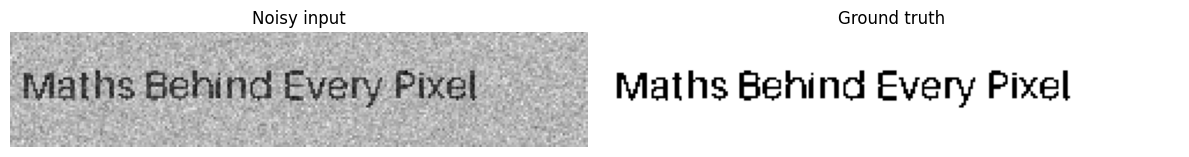

In [ ]:
rng = np.random.default_rng(0)

# Create a white image with black text
img = Image.new("L", (500, 100), 255)
draw = ImageDraw.Draw(img)

font = ImageFont.load_default(size=35)
draw.text((10, 25), "Maths Behind Every Pixel", font=font, fill=0)

# Resize the image
img = img.resize((250, 50))

# Create the ground truth and noisy input
gt = (1 - np.array(img) / 255 > 0.5).astype(float)
noisy = gt + 0.15 * rng.standard_normal(gt.shape)
u0 = normalize(noisy)

# Display the images
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].imshow(u0, cmap="gray_r", vmin=0, vmax=1)
ax[0].set_title("Noisy input")

ax[1].imshow(gt, cmap="gray_r", vmin=0, vmax=1)
ax[1].set_title("Ground truth")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


Sweep $\alpha$.
For each $\alpha$ we run the solver and record the L1 error at every step. We print the best error and the step where it occurs (the ideal **stopping time**), plus the final error, to see how much it drifts if we run too long.

In [ ]:

alphas = [1, 0.8, 0.75, 0.6, 0.5, 0.25]
LAM = 0.05
N_STEPS = 200

results = {}

for a in alphas:
    dt = dt_from_lambda(a, LAM)
    traj = solve(u0, a, dt, N_STEPS)

    errors = [l1_error(u, gt) for u in traj]
    results[a] = (traj, errors)

    print("alpha:", a)
    print("Best error:", round(min(errors), 2), "%")
    print("Best step:", np.argmin(errors))
    print("Final error:", round(errors[-1], 2), "%")


alpha: 1
Best error: 0.01 %
Best step: 4
Final error: 0.02 %
alpha: 0.8
Best error: 0.01 %
Best step: 4
Final error: 0.02 %
alpha: 0.75
Best error: 0.01 %
Best step: 4
Final error: 0.02 %
alpha: 0.6
Best error: 0.01 %
Best step: 4
Final error: 0.02 %
alpha: 0.5
Best error: 0.01 %
Best step: 4
Final error: 0.02 %
alpha: 0.25
Best error: 0.01 %
Best step: 5
Final error: 0.02 %


## error curves (the analogue of the paper's Fig. 8).
 A curve that dips and then rises means over-diffusion, so stopping early matters. A flat curve means stable behavior.

saved: plots/64_figure.png


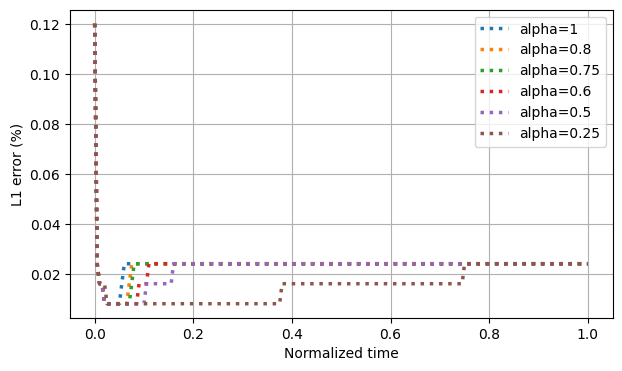

In [ ]:

plt.figure(figsize=(7, 4))

for a, (_, errors) in results.items():
    time = np.arange(len(errors)) / N_STEPS
    plt.plot(time, errors, ":", linewidth=2.5, label=f"alpha={a}")

plt.xlabel("Normalized time")
plt.ylabel("L1 error (%)")
plt.legend()
plt.grid(alpha=1)
plt.show()


For each $\alpha$ we show the binarized result at its best stopping step and at the final step, so you can see the quality difference.

saved: plots/65_1_best.png


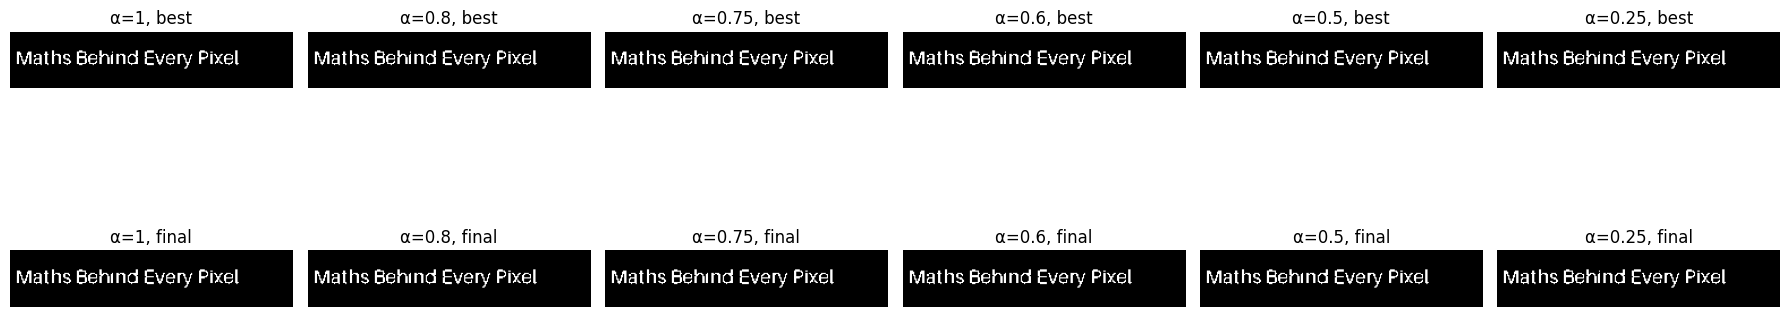

In [ ]:

fig, axes = plt.subplots(2, len(alphas), figsize=(3 * len(alphas), 6))

for j, a in enumerate(alphas):
    traj, errors = results[a]
    best = np.argmin(errors)

    axes[0, j].imshow(traj[best] > 0.5, cmap="gray")
    axes[0, j].set_title(f"α={a}, best")

    axes[1, j].imshow(traj[-1] > 0.5, cmap="gray")
    axes[1, j].set_title(f"α={a}, final")

    axes[0, j].axis("off")
    axes[1, j].axis("off")

plt.tight_layout()
plt.show()


## Comparing $c_s = 1$, $c_s = 25$ and $c_s = 50$ Using Error Measurements and Plots

In [ ]:
comparison = {}

for cs in [1,25,50]:
    results_cs = {}

    for alpha in alphas:
        dt = dt_from_lambda(alpha, LAM)

        traj = solve(
            u0, alpha, dt, N_STEPS,
            a=0.5, c_d=1.0, c_s=cs
        )

        errors = [l1_error(u, gt) for u in traj]
        results_cs[alpha] = (traj, errors)

        print(
            f"c_s={cs}, alpha={alpha}, "
            f"best error={min(errors):.2f}%, "
            f"final error={errors[-1]:.2f}%"
        )

    comparison[cs] = results_cs

c_s=1, alpha=1, best error=0.01%, final error=6.42%
c_s=1, alpha=0.8, best error=0.02%, final error=6.35%
c_s=1, alpha=0.75, best error=0.02%, final error=6.14%
c_s=1, alpha=0.6, best error=0.01%, final error=3.00%
c_s=1, alpha=0.5, best error=0.01%, final error=1.02%
c_s=1, alpha=0.25, best error=0.01%, final error=0.03%
c_s=25, alpha=1, best error=0.01%, final error=3.85%
c_s=25, alpha=0.8, best error=0.01%, final error=2.85%
c_s=25, alpha=0.75, best error=0.01%, final error=2.61%
c_s=25, alpha=0.6, best error=0.01%, final error=1.98%
c_s=25, alpha=0.5, best error=0.01%, final error=1.29%
c_s=25, alpha=0.25, best error=0.01%, final error=0.07%
c_s=50, alpha=1, best error=0.01%, final error=0.02%
c_s=50, alpha=0.8, best error=0.01%, final error=0.02%
c_s=50, alpha=0.75, best error=0.01%, final error=0.02%
c_s=50, alpha=0.6, best error=0.01%, final error=0.02%
c_s=50, alpha=0.5, best error=0.01%, final error=0.02%
c_s=50, alpha=0.25, best error=0.01%, final error=0.02%


saved: plots/66_Error_curves_c_s_1.png


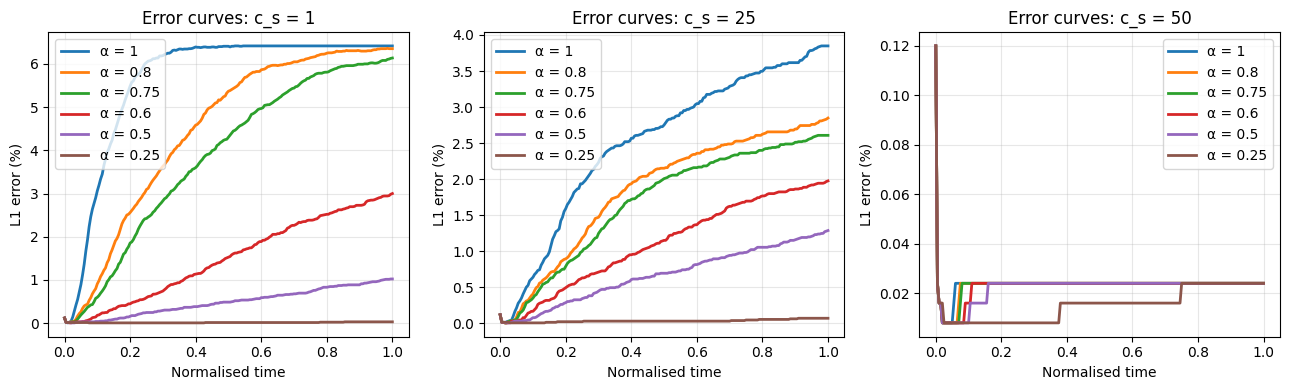

In [ ]:
fig, axes = plt.subplots(1,3,figsize=(13, 4))

for ax, cs in zip(axes, [1,25, 50]):
    for alpha, (traj, errors) in comparison[cs].items():
        time = np.linspace(0, 1, len(errors))

        ax.plot(
            time, errors,
            linewidth=2,
            label=f"α = {alpha}"
        )

    ax.set_title(f"Error curves: c_s = {cs}")
    ax.set_xlabel("Normalised time")
    ax.set_ylabel("L1 error (%)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

saved: plots/67_Final_error.png


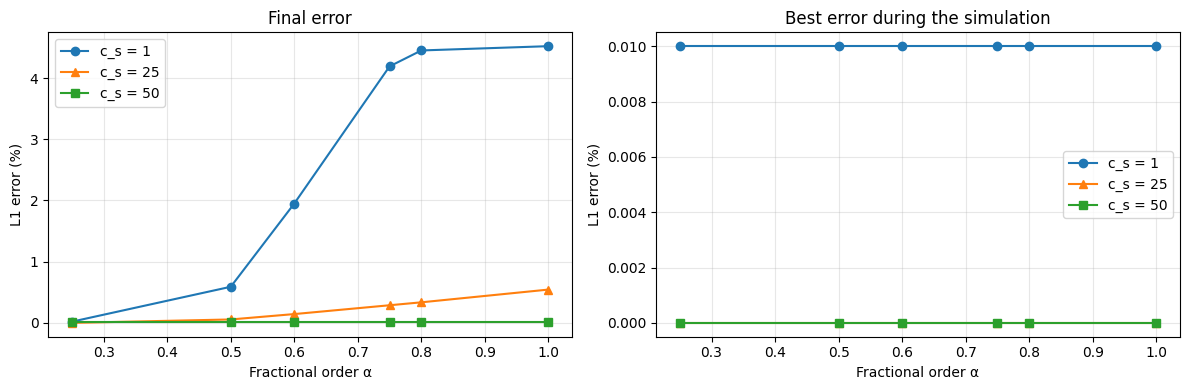

In [ ]:


import numpy as np
import matplotlib.pyplot as plt

alphas = np.array([1, 0.8, 0.75, 0.6, 0.5, 0.25])

best_1 = np.array([0.01, 0.01, 0.01, 0.01, 0.01, 0.01])
final_1 = np.array([4.52, 4.45, 4.19, 1.95, 0.59, 0.02])

best_25 = np.array([0, 0, 0, 0, 0, 0])
final_25 = np.array([0.544, 0.336, 0.288, 0.144, 0.056, 0.0])

best_50 = np.array([0, 0, 0, 0, 0, 0])
final_50 = np.array([0.01, 0.01, 0.01, 0.01, 0.01, 0.01])

# Sort fractional orders
order = np.argsort(alphas)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Final errors
axes[0].plot(alphas[order], final_1[order], "o-", label="c_s = 1")
axes[0].plot(alphas[order], final_25[order], "^-", label="c_s = 25")
axes[0].plot(alphas[order], final_50[order], "s-", label="c_s = 50")

axes[0].set_title("Final error")
axes[0].set_xlabel("Fractional order α")
axes[0].set_ylabel("L1 error (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Best errors
axes[1].plot(alphas[order], best_1[order], "o-", label="c_s = 1")
axes[1].plot(alphas[order], best_25[order], "^-", label="c_s = 25")
axes[1].plot(alphas[order], best_50[order], "s-", label="c_s = 50")

axes[1].set_title("Best error during the simulation")
axes[1].set_xlabel("Fractional order α")
axes[1].set_ylabel("L1 error (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


##Analysing how much the errors change

In [ ]:

import pandas as pd

analysis = pd.DataFrame({
    "Alpha": alphas,
    "Final error (cs=1)": final_1,
    "Final error (cs=25)": final_25,
    "Final error (cs=50)": final_50
})

analysis["Error reduction (cs=1 to cs=25)"] = (
    analysis["Final error (cs=1)"]
    - analysis["Final error (cs=25)"]
)

analysis["Error reduction (cs=1 to cs=50)"] = (
    analysis["Final error (cs=1)"]
    - analysis["Final error (cs=50)"]
)

analysis["Relative reduction for cs=25 (%)"] = (
    analysis["Error reduction (cs=1 to cs=25)"]
    / analysis["Final error (cs=1)"] * 100
)

analysis["Relative reduction for cs=50 (%)"] = (
    analysis["Error reduction (cs=1 to cs=50)"]
    / analysis["Final error (cs=1)"] * 100
)

display(analysis.round(3))



,Alpha,Final error (cs=1),Final error (cs=25),Final error (cs=50),Error reduction (cs=1 to cs=25),Error reduction (cs=1 to cs=50),Relative reduction for cs=25 (%),Relative reduction for cs=50 (%)
0,1.00,4.52,0.544,0.01,3.976,4.51,87.965,99.779
1,0.80,4.45,0.336,0.01,4.114,4.44,92.449,99.775
2,0.75,4.19,0.288,0.01,3.902,4.18,93.126,99.761
3,0.60,1.95,0.144,0.01,1.806,1.94,92.615,99.487
4,0.50,0.59,0.056,0.01,0.534,0.58,90.508,98.305
5,0.25,0.02,0.000,0.01,0.020,0.01,100.000,50.000


### For presentation: Discussion of Results

The aim of this experiment was to investigate how the reaction coefficient $c_s$ and the fractional order $\alpha$ affect image binarization using a time-fractional diffusion-reaction equation. The performance was measured using the L1 error, which represents the percentage of pixels incorrectly classified after thresholding the solution at $0.5$. A lower error indicates a closer match to the ground-truth image.

#### Effect of the Reaction Coefficient $c_s$

The reaction coefficient was tested using $c_s=1$ and $c_s=50$, while keeping the diffusion coefficient fixed at $c_d=1$ and the parameter $a=0.5$.

When $c_s=1$, the final error decreased as $\alpha$ decreased. The error was $4.52\%$ for $\alpha=1$, compared with $1.95\%$ for $\alpha=0.6$, $0.59\%$ for $\alpha=0.5$, and $0.02\%$ for $\alpha=0.25$. These results suggest that, for this image and these numerical settings, smaller fractional orders produced better final binarization results.

When the reaction coefficient was increased to $c_s=50$, the final error was approximately $0.01\%$ for all tested values of $\alpha$. This is a substantial improvement compared with the results obtained using $c_s=1$. The stronger reaction term encourages pixel values to move towards the binary states $0$ and $1$. This can help separate the text from the background and reduce the number of incorrectly classified pixels.

However, the results for $c_s=50$ show very little difference between the fractional orders at the final time. One possible explanation is that the stronger reaction term dominates the evolution sufficiently that differences caused by $\alpha$ become less visible in the final binary images. Further investigation is needed to confirm this explanation.

#### Effect of the Fractional Order $\alpha$

The fractional order determines how the solution evolves over time. When $\alpha=1$, the equation uses the classical first-order time derivative. When $0<\alpha<1$, the Caputo fractional derivative accounts for the history of the solution.

The diffusion term smooths variations in pixel values, helping to reduce noise. However, excessive smoothing can also weaken the boundaries of the text and cause some characters to lose their shape. The reaction term counteracts this by encouraging pixel values towards $0$ or $1$.

For $c_s=1$, the results indicate that reducing $\alpha$ improved the final binarization accuracy. In particular, $\alpha=0.5$ produced a final error of $0.59\%$, while $\alpha=0.25$ produced the lowest final error of $0.02\%$. This suggests that the memory effect associated with the fractional derivative may help preserve useful image information during the processing of this particular noisy input.

For $c_s=50$, however, all tested fractional orders produced almost identical final errors. This indicates that the choice of reaction coefficient can strongly influence whether differences between the fractional orders are visible in the final results.

It is important to note that the fractional order does not change the initial noisy image itself. Instead, it changes how the solution evolves from that initial image over time. The effects of $\alpha$ should therefore be examined by comparing the processed images and error curves at different time steps, rather than considering only the initial image or the final error.

#### Best Error and Final Error

The best error records the lowest error reached during the simulation, whereas the final error measures the error at the last time step. For $c_s=1$, the best error was approximately $0.01\%$ for all tested fractional orders, even though their final errors differed considerably. This suggests that some solutions reached a highly accurate binary image at an intermediate time and subsequently became less accurate.

This distinction is important because continued diffusion and reaction do not necessarily improve the image indefinitely. Selecting a suitable stopping time can therefore be important for obtaining the best result.

For $c_s=50$, the reported best errors were $0.00\%$ and the final errors were approximately $0.01\%$. These values indicate near-perfect classification at the reported precision. Since the errors are very small, their interpretation should also account for the image resolution and the rounding of the reported percentages.

#### Conclusion

The experiments show that both the reaction coefficient $c_s$ and the fractional order $\alpha$ influence the binarization results. Increasing $c_s$ from $1$ to $50$ substantially reduced the final error for the tested image, while decreasing $\alpha$ improved the final results when $c_s=1$. When $c_s=50$, the final errors were almost independent of $\alpha$.

These findings suggest that the balance between diffusion and reaction is important for image binarization, and that the fractional order can influence how well image details are preserved during the evolution. However, these conclusions apply to the current test image and numerical settings. Additional experiments with different images, reaction coefficients, time steps, and stopping times are needed before drawing general conclusions or determining whether the results reproduce the behaviour reported in the research paper.

# Presentation plot for reference during the presentation

saved: plots/68_Numerical_solutions_c_s_1.png


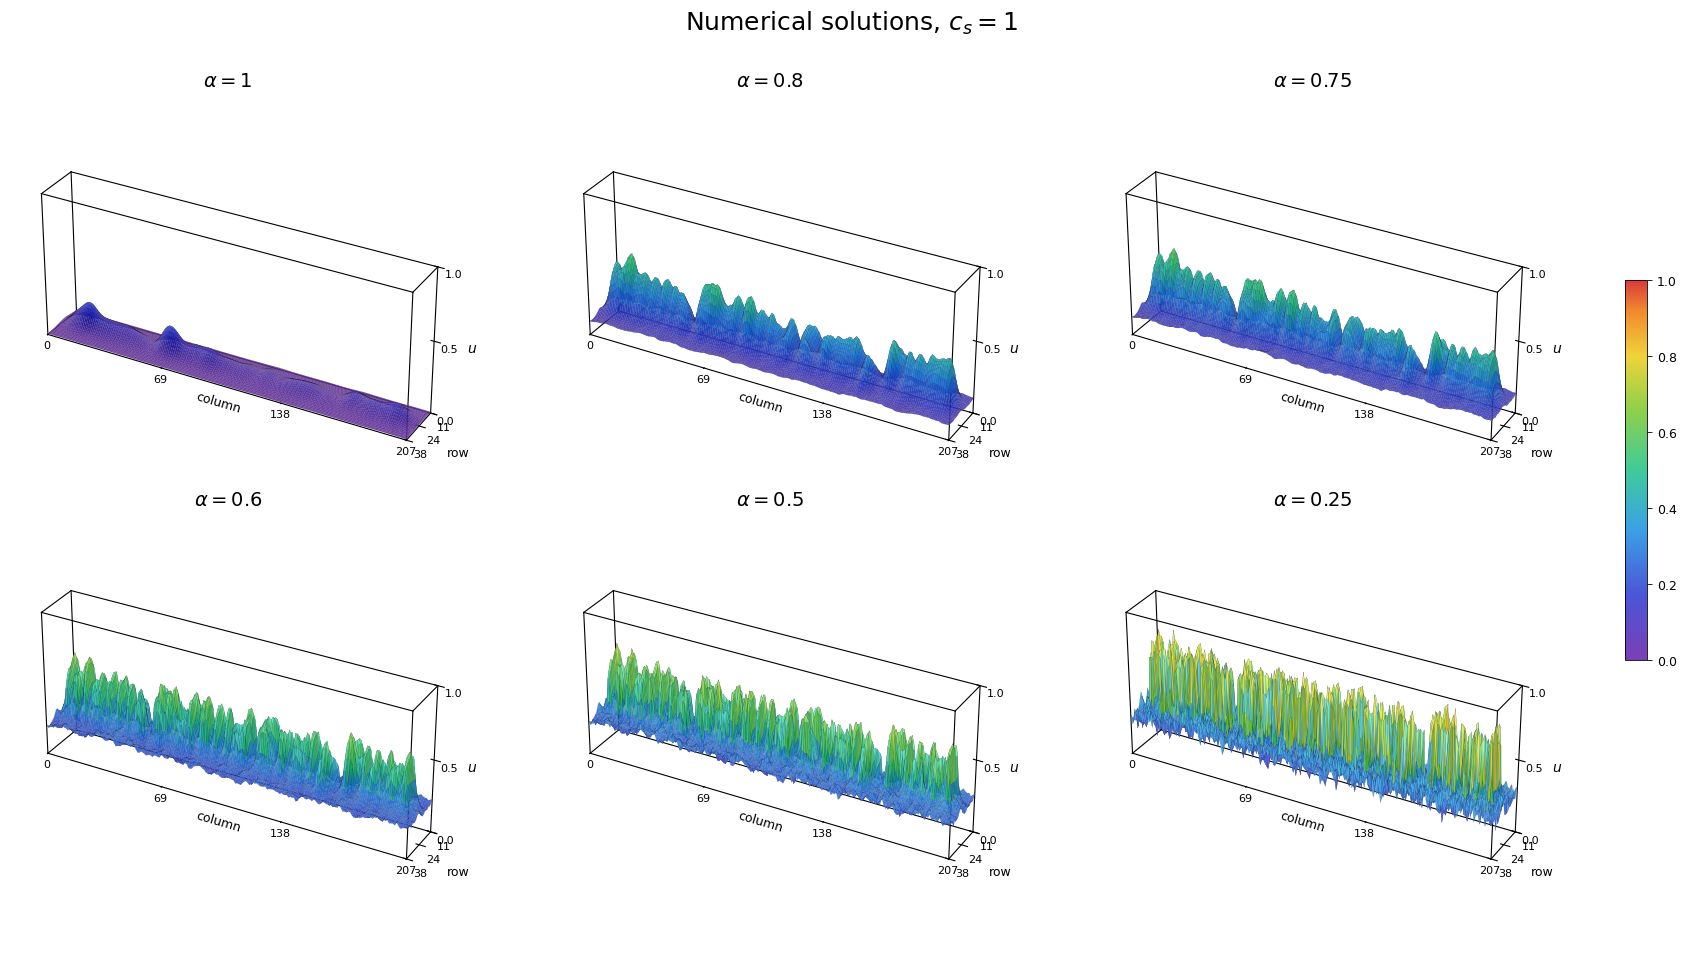

saved: plots/69_Numerical_solutions_c_s_25.png


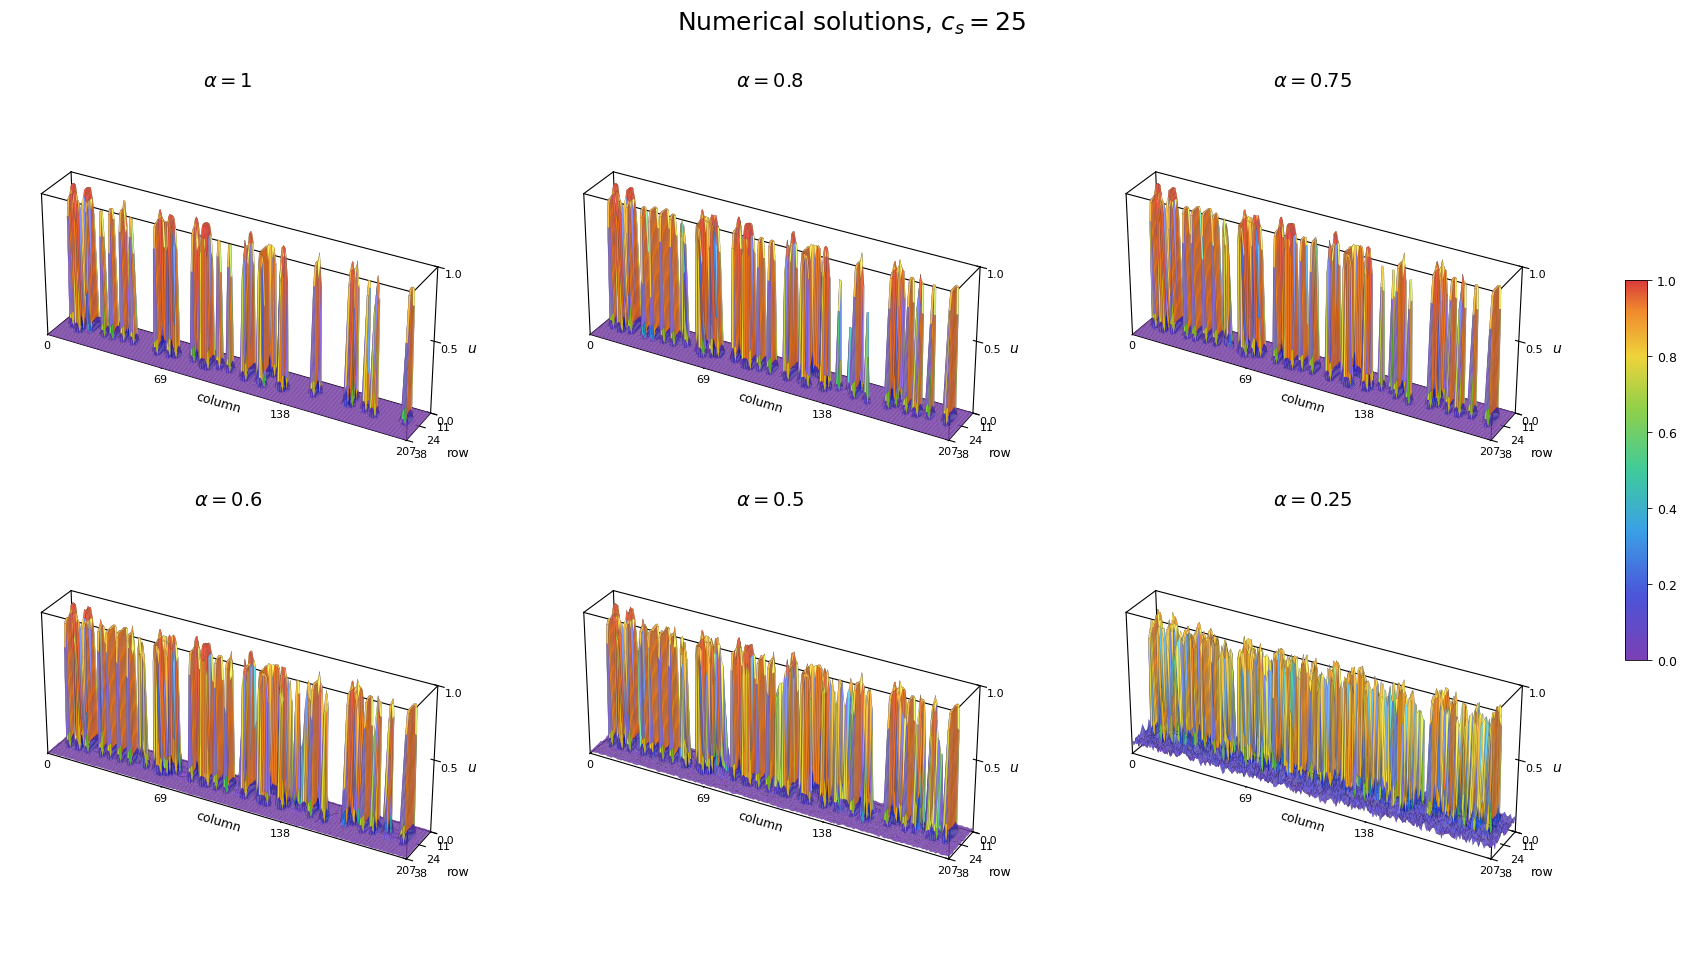

saved: plots/70_Numerical_solutions_c_s_50.png


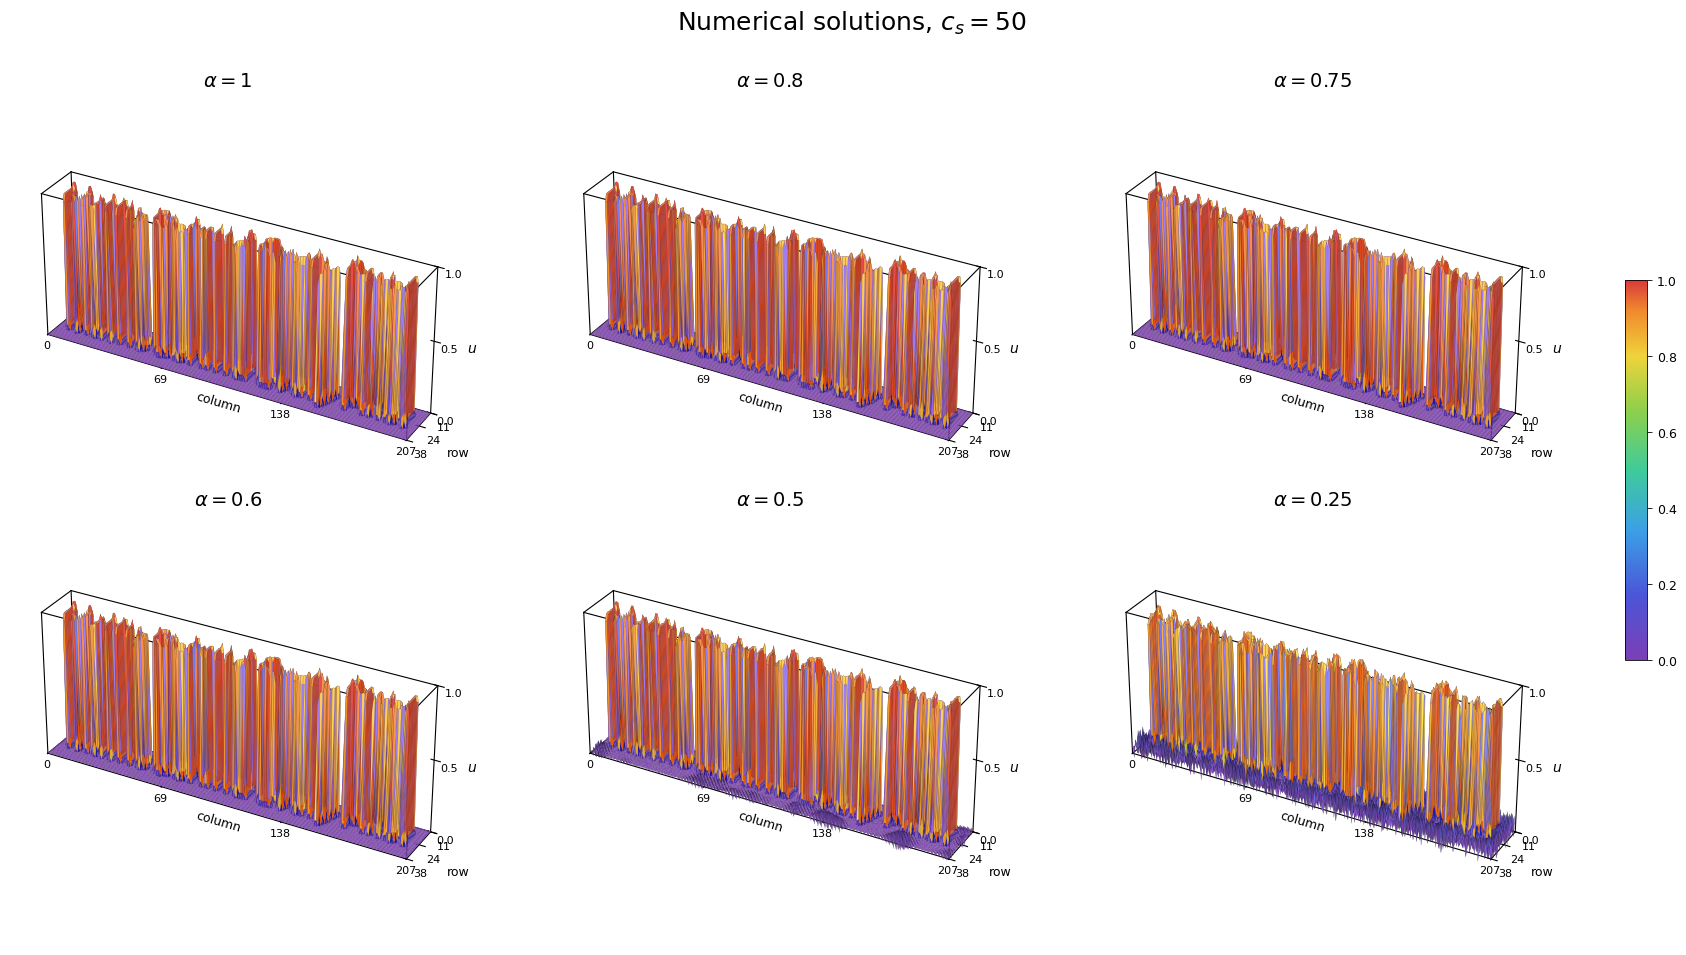

In [ ]:

alphas = [1, 0.8, 0.75, 0.6, 0.5, 0.25]
cs_values = [1, 25, 50]

STEP = 1                 # 1 = every pixel (smoothest). Use 2 for a coarser mesh
SHARED_SCALE = True      # True: same 0-1 height/colour scale in every panel
CROP_TO_TEXT = True      # zoom in on the text region
PAD = 6

# Approximation of Mathematica's ColorFunction -> "Rainbow"
mma_rainbow = LinearSegmentedColormap.from_list("mma_rainbow", [
    (0.00, "#7B3FB5"), (0.17, "#4B55D8"), (0.34, "#3BA0E6"),
    (0.50, "#3FCB9A"), (0.66, "#8FD04A"), (0.80, "#EFD33A"),
    (0.92, "#F08A2E"), (1.00, "#D93A3A")], N=256)


u_exact = np.squeeze(np.asarray(gt))
if u_exact.ndim != 2:
    raise ValueError("gt must be a 2D reference image.")

if CROP_TO_TEXT:
    r_idx, c_idx = np.where(u_exact > 0.5)
    r0 = max(r_idx.min() - PAD, 0);  r1 = min(r_idx.max() + PAD + 1, u_exact.shape[0])
    c0 = max(c_idx.min() - PAD, 0);  c1 = min(c_idx.max() + PAD + 1, u_exact.shape[1])
else:
    r0, r1, c0, c1 = 0, u_exact.shape[0], 0, u_exact.shape[1]

rows = np.arange(r0, r1, STEP)
cols = np.arange(c0, c1, STEP)
X, Y = np.meshgrid(cols, rows)
nx, ny = c1 - c0, r1 - r0

light = LightSource(azdeg=315, altdeg=45)

def draw_box(ax, xlim, ylim, zlim, **kw):
    """The thin black bounding box Mathematica draws around 3D plots."""
    (x0, x1), (y0, y1), (z0, z1) = xlim, ylim, zlim
    for a in (y0, y1):
        for b in (z0, z1):
            ax.plot([x0, x1], [a, a], [b, b], **kw)
    for a in (x0, x1):
        for b in (z0, z1):
            ax.plot([a, a], [y0, y1], [b, b], **kw)
    for a in (x0, x1):
        for b in (y0, y1):
            ax.plot([a, a], [b, b], [z0, z1], **kw)

# ------------------------------------------------------------------

for cs in cs_values:
    fig = plt.figure(figsize=(18, 9.5), facecolor="white")

    sols = {a: np.asarray(comparison[cs][a][0][-1]).squeeze() for a in alphas}
    for a, u in sols.items():
        if u.shape != u_exact.shape:
            raise ValueError(f"Shape mismatch for cs={cs}, alpha={a}.")

    for k, alpha in enumerate(alphas, start=1):
        ax = fig.add_subplot(2, 3, k, projection="3d")
        u = sols[alpha][np.ix_(rows, cols)]

        lo, hi = (0.0, 1.0) if SHARED_SCALE else (u.min(), u.max())
        norm = Normalize(lo, hi)

        colours = light.shade(u, cmap=mma_rainbow, norm=norm,
                              blend_mode="soft", vert_exag=1.2,
                              dx=STEP, dy=STEP)
        ax.plot_surface(X, Y, u, facecolors=colours,
                        rstride=1, cstride=1, shade=False,
                        edgecolor=(0, 0, 0, 0.28), linewidth=0.2,
                        antialiased=True)

        xl, yl, zl = (c0, c1 - 1), (r1 - 1, r0), (lo, hi)
        ax.set_xlim(*xl); ax.set_ylim(*yl); ax.set_zlim(*zl)
        draw_box(ax, xl, (r0, r1 - 1), zl, color="k", lw=0.8)

        ax.set_box_aspect((nx, ny, 0.40 * nx))
        ax.view_init(elev=30, azim=-61)

        # Mathematica look: white, no panes, no grid, small ticks
        ax.grid(False)
        for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
            axis.set_pane_color((1, 1, 1, 0))
            axis.line.set_color((0, 0, 0, 0))
        ax.set_xticks(np.linspace(c0, c1 - 1, 4).astype(int))
        ax.set_yticks(np.linspace(r0, r1 - 1, 3).astype(int))
        ax.set_zticks(np.linspace(lo, hi, 3))
        ax.tick_params(labelsize=8, pad=-2)
        ax.set_xlabel("column", fontsize=9, labelpad=-4)
        ax.set_ylabel("row", fontsize=9, labelpad=-4)
        ax.set_zlabel(r"$u$", fontsize=10, labelpad=-6)
        ax.set_title(rf"$\alpha = {alpha}$", fontsize=14, pad=-14)

    # Bar legend, as in Mathematica's BarLegend
    cax = fig.add_axes([0.93, 0.30, 0.012, 0.40])
    cbar = fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap=mma_rainbow),
                        cax=cax, ticks=np.linspace(0, 1, 6))
    cbar.outline.set_linewidth(0.6)
    cbar.ax.tick_params(labelsize=9, width=0.6)

    fig.suptitle(rf"Numerical solutions, $c_s = {cs}$", fontsize=18, y=0.985)
    fig.subplots_adjust(left=0.0, right=0.91, bottom=0.0, top=0.90,
                        wspace=-0.02, hspace=-0.04)

    plt.savefig(f"numerical_solutions_mathematica_cs{cs}.png", dpi=200,
                bbox_inches="tight", facecolor="white")
    plt.show()

saved: plots/71_Numerical_solutions_for_alpha_1.png


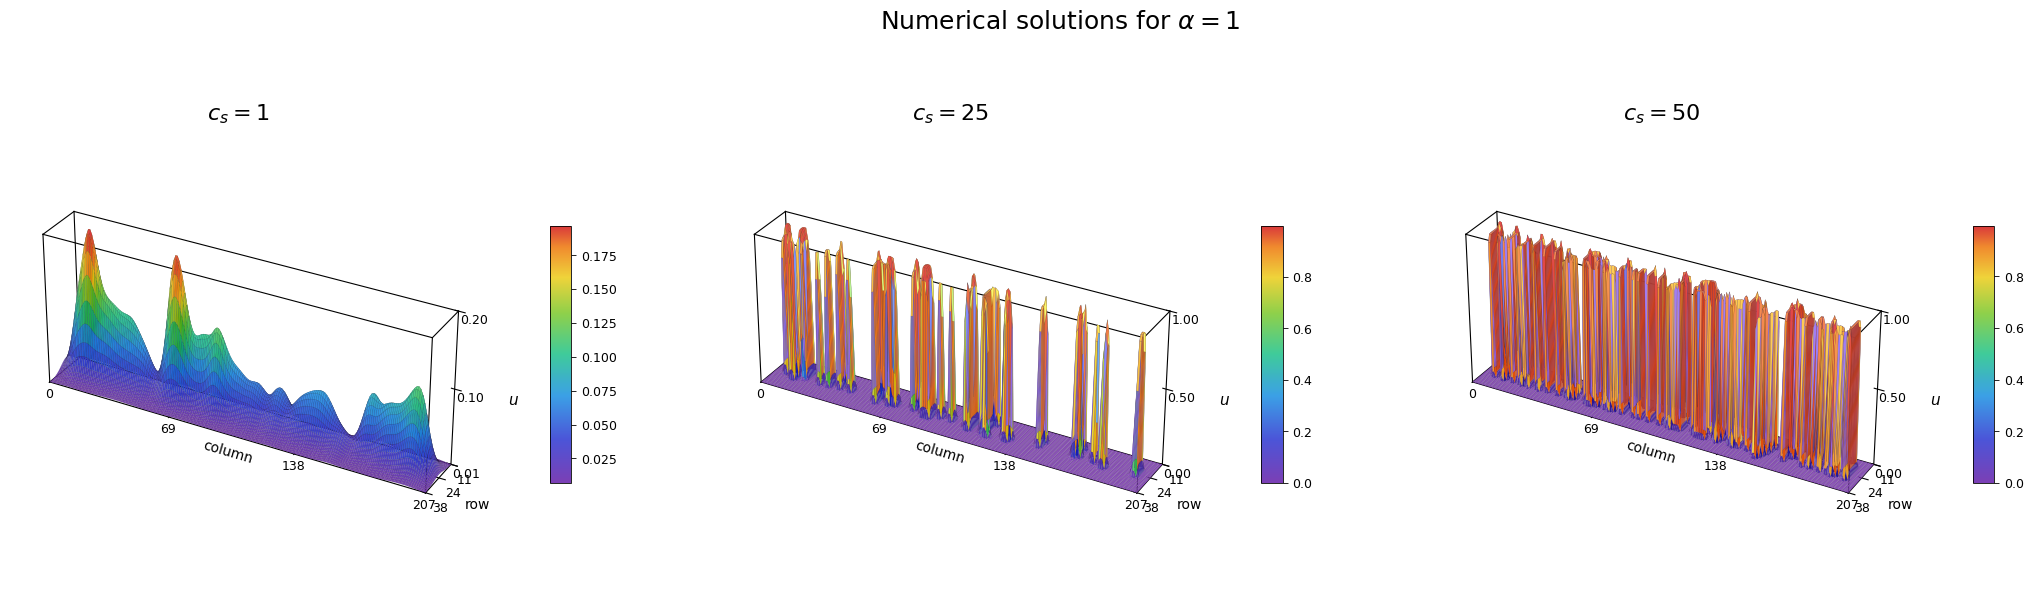

In [ ]:

alpha = 1
cs_values = [1, 25, 50]

OWN_SCALE = True     # True: each panel uses its own height/colour range (Mathematica default)
                     # False: all panels share a fixed 0-1 range
PAD = 6

# Approximation of Mathematica's ColorFunction -> "Rainbow"
mma_rainbow = LinearSegmentedColormap.from_list("mma_rainbow", [
    (0.00, "#7B3FB5"), (0.17, "#4B55D8"), (0.34, "#3BA0E6"),
    (0.50, "#3FCB9A"), (0.66, "#8FD04A"), (0.80, "#EFD33A"),
    (0.92, "#F08A2E"), (1.00, "#D93A3A")], N=256)


u_exact = np.squeeze(np.asarray(gt))
if u_exact.ndim != 2:
    raise ValueError("gt must be a 2D reference image.")

# Zoom in on the text region
r_idx, c_idx = np.where(u_exact > 0.5)
r0 = max(r_idx.min() - PAD, 0);  r1 = min(r_idx.max() + PAD + 1, u_exact.shape[0])
c0 = max(c_idx.min() - PAD, 0);  c1 = min(c_idx.max() + PAD + 1, u_exact.shape[1])

X, Y = np.meshgrid(np.arange(c0, c1), np.arange(r0, r1))
nx, ny = c1 - c0, r1 - r0
light = LightSource(azdeg=315, altdeg=45)

def draw_box(ax, xlim, ylim, zlim, **kw):
    """Thin black bounding box, as Mathematica draws around 3D plots."""
    (x0, x1), (y0, y1), (z0, z1) = xlim, ylim, zlim
    for a in (y0, y1):
        for b in (z0, z1):
            ax.plot([x0, x1], [a, a], [b, b], **kw)
    for a in (x0, x1):
        for b in (z0, z1):
            ax.plot([a, a], [y0, y1], [b, b], **kw)
    for a in (x0, x1):
        for b in (y0, y1):
            ax.plot([a, a], [b, b], [z0, z1], **kw)


fig = plt.figure(figsize=(21, 6.5), facecolor="white")

for k, cs in enumerate(cs_values, start=1):
    ax = fig.add_subplot(1, len(cs_values), k, projection="3d")

    traj, _ = comparison[cs][alpha]
    u_full = np.asarray(traj[-1]).squeeze()
    if u_full.shape != u_exact.shape:
        raise ValueError(f"Shape mismatch for cs={cs}.")
    u = u_full[r0:r1, c0:c1]

    lo, hi = (u.min(), u.max()) if OWN_SCALE else (0.0, 1.0)
    norm = Normalize(lo, hi)

    colours = light.shade(u, cmap=mma_rainbow, norm=norm,
                          blend_mode="soft", vert_exag=1.2 * (hi - lo))
    ax.plot_surface(X, Y, u, facecolors=colours, rstride=1, cstride=1,
                    shade=False, edgecolor=(0, 0, 0, 0.28), linewidth=0.2,
                    antialiased=True)

    xl, yl, zl = (c0, c1 - 1), (r1 - 1, r0), (lo, hi)
    ax.set_xlim(*xl); ax.set_ylim(*yl); ax.set_zlim(*zl)
    draw_box(ax, xl, (r0, r1 - 1), zl, color="k", lw=0.8)

    ax.set_box_aspect((nx, ny, 0.40 * nx))
    ax.view_init(elev=30, azim=-61)

    ax.grid(False)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((1, 1, 1, 0))
        axis.line.set_color((0, 0, 0, 0))
    ax.set_xticks(np.linspace(c0, c1 - 1, 4).astype(int))
    ax.set_yticks(np.linspace(r0, r1 - 1, 3).astype(int))
    ax.set_zticks(np.linspace(lo, hi, 3))
    ax.zaxis.set_major_formatter("{x:.2f}")
    ax.tick_params(labelsize=9, pad=-2)
    ax.set_xlabel("column", fontsize=10, labelpad=-4)
    ax.set_ylabel("row", fontsize=10, labelpad=-4)
    ax.set_zlabel(r"$u$", fontsize=11, labelpad=2)
    ax.set_title(rf"$c_s = {cs}$", fontsize=16, pad=-14)

    # Bar legend for this panel
    cbar = fig.colorbar(ScalarMappable(norm=norm, cmap=mma_rainbow),
                        ax=ax, shrink=0.45, aspect=12, pad=0.13)
    cbar.outline.set_linewidth(0.6)
    cbar.ax.tick_params(labelsize=9, width=0.6)

fig.suptitle(r"Numerical solutions for $\alpha = 1$", fontsize=18, y=0.97)
fig.subplots_adjust(left=0.0, right=0.98, bottom=0.0, top=0.88, wspace=0.12)

plt.savefig("numerical_solutions_alpha1.png", dpi=200,
            bbox_inches="tight", facecolor="white")
plt.show()